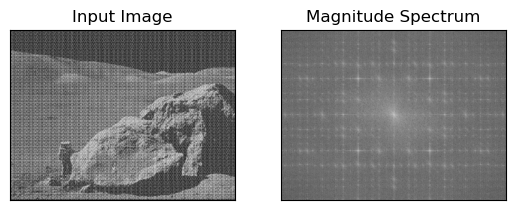

In [128]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
from skimage.feature import peak_local_max
 
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
 
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
 
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))
 
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

In [129]:
#Filter creating
# Low pass filter
mask = np.zeros((img.shape[0],img.shape[1],2),np.uint8)
centerX, centerY = (int(img.shape[0] / 2),int(img.shape[1] / 2))
mask[centerX-50:centerX+50, centerY - 50:centerY+50,:] = 1

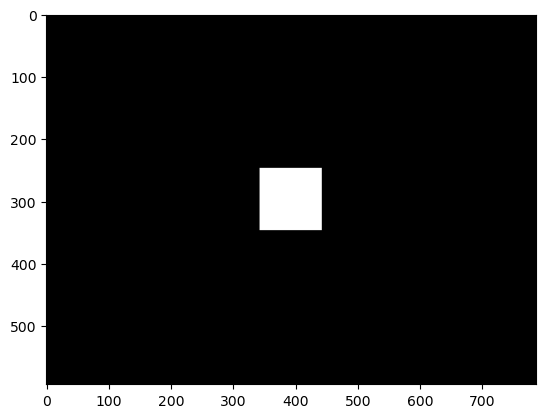

In [130]:
plt.imshow(mask[:,:,0], cmap = 'gray')

In [131]:
# Filtering
dft_shift = dft_shift*mask

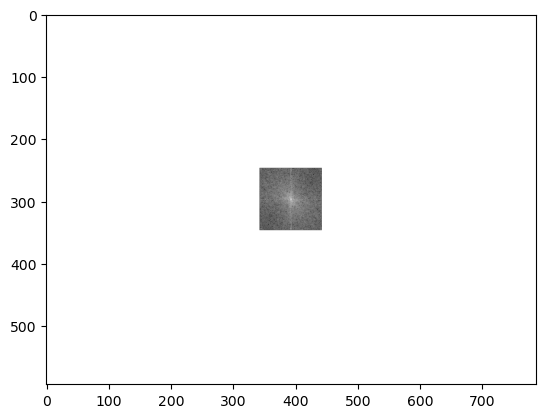

In [132]:
filtering_magn_res = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))
plt.imshow(filtering_magn_res, cmap='gray')

In [133]:
#fshift = dft_shift*mask
f_ishift = np.fft.ifftshift(dft_shift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0],img_back[:,:,1])

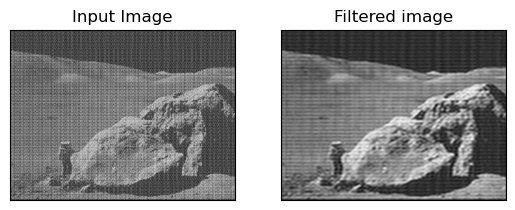

In [134]:
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_back, cmap = 'gray')
plt.title('Filtered image'), plt.xticks([]), plt.yticks([])
plt.show()

In [135]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье

# Задание 1. Высокочастотная фильтрация на основе ядра Гаусса

In [136]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE) 

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft, axes=(0, 1))

In [137]:
rows, cols = img.shape
centerX, centerY = rows // 2, cols // 2
x, y = np.ogrid[:rows, :cols]
sigma = 50
gauss = np.exp(-((x-centerX)**2 + (y-centerY)**2)/(2*sigma**2))
mask_gauss = 1 - gauss
mask = np.repeat(mask_gauss[:, :, np.newaxis], 2, axis=2).astype(np.float32)

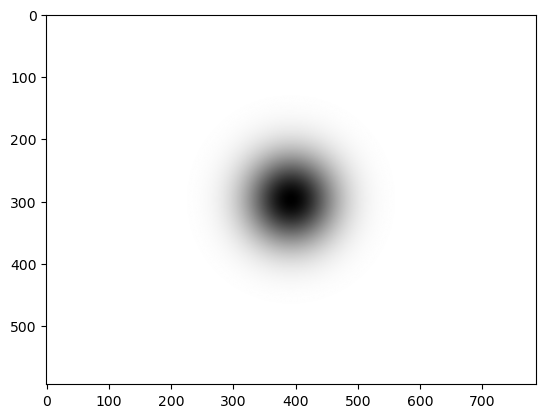

In [138]:
plt.imshow(mask[:,:,0], cmap='gray')
plt.show()

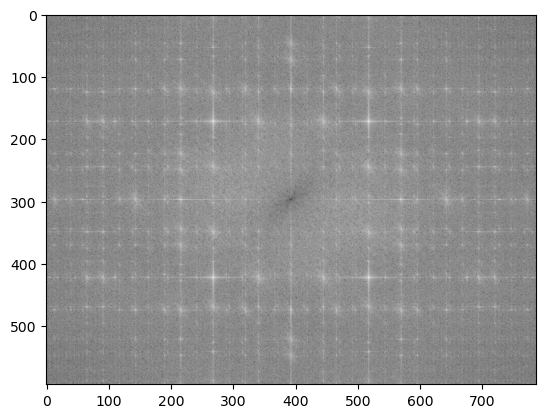

In [139]:
filtered_dft = dft_shift * mask
filtering_magn_res = 20*np.log1p(cv.magnitude(filtered_dft[:,:,0], filtered_dft[:,:,1]))
plt.imshow(filtering_magn_res, cmap='gray')
plt.show()

In [140]:
f_ishift = np.fft.ifftshift(filtered_dft, axes=(0, 1))
img_back = cv.idft(f_ishift, flags=cv.DFT_SCALE)
img_back = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

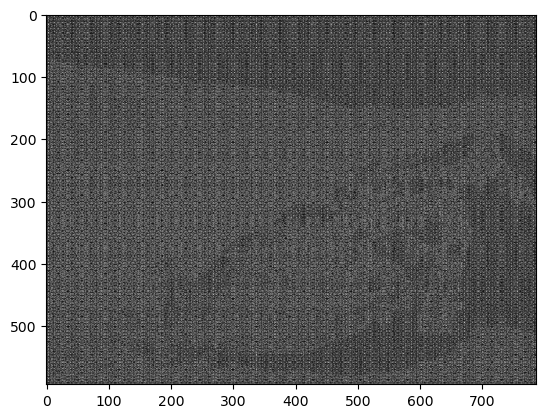

In [141]:
plt.imshow(img_back, cmap='gray')

# Задание 2. Вычисление свёртки с помощью преобразования Фурье

In [142]:
rows, cols = img.shape
kernel = np.ones((5, 5), np.float32) / 25
padded = np.zeros((rows, cols), np.float32)
padded[:5, :5] = kernel
padded = np.roll(padded, (-2, -2), axis=(0, 1))

dft_kernel = cv.dft(padded, flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel_shift = np.fft.fftshift(dft_kernel, axes=(0, 1))

In [143]:
dft_shift = cv.mulSpectrums(dft_shift,dft_kernel_shift,flags=0)

In [144]:
filtering_magn_res = 20*np.log(cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]) + 1)

In [145]:
f_ishift = np.fft.ifftshift(dft_shift, axes=(0, 1))
img_back = cv.idft(f_ishift, flags=cv.DFT_SCALE)
img_back = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

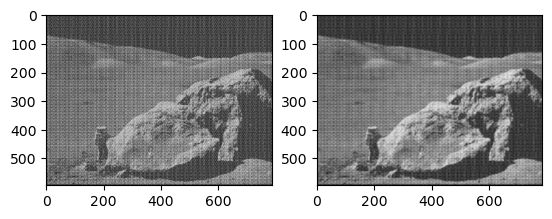

In [146]:
plt.subplot(121),plt.imshow(img, cmap='gray')
plt.subplot(122),plt.imshow(img_back, cmap='gray')
plt.show()

# Задание 3. Удаление периодического шума с помощью преобразования Фурье

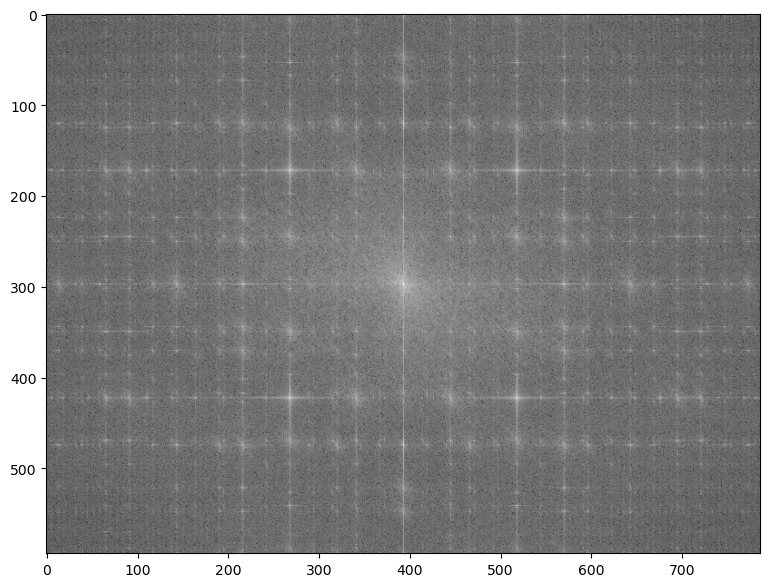

In [147]:
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft, axes=(0, 1))
magnitude_spectrum = 20*np.log1p(cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]))
plt.figure(figsize=(10, 7))
plt.imshow(magnitude_spectrum, cmap='gray')
plt.show()

In [204]:
rows, cols = img.shape
centerX, centerY = rows // 2, cols // 2

local_max = peak_local_max(magnitude_spectrum,min_distance=15,threshold_abs=220)

mask = np.ones((rows, cols, 2), dtype=np.uint8)

In [210]:
radius = min(rows, cols) * 0.05
count = 0
for y, x in local_max:
    distance = np.sqrt((x - centerY)**2 + (y - centerX)**2)
    if distance > radius:
        cv.circle(mask, (x, y), 5, (0, 0), -1)
        cv.circle(mask, ((cols-x) % cols, (rows-y) % rows), 5, (0, 0), -1)
        count += 1

print("Количество пиков:", count)

Количество пиков: 370


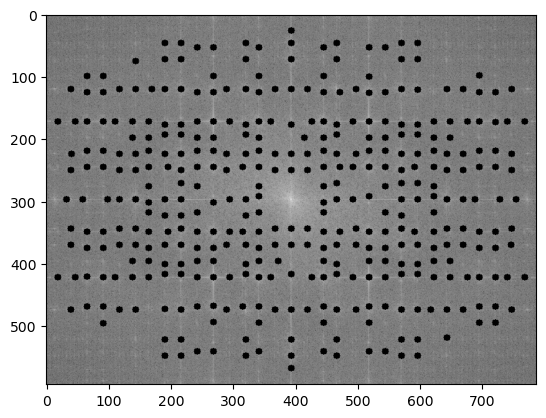

In [211]:
filtered_dft = dft_shift * mask

filtered_spectrum = 20 * np.log(cv.magnitude(filtered_dft[:,:,0], filtered_dft[:,:,1]) + 1)

plt.imshow(filtered_spectrum, cmap='gray')
plt.show()

In [212]:
f_ishift = np.fft.ifftshift(filtered_dft, axes=(0, 1))
img_idft = cv.idft(f_ishift, flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)

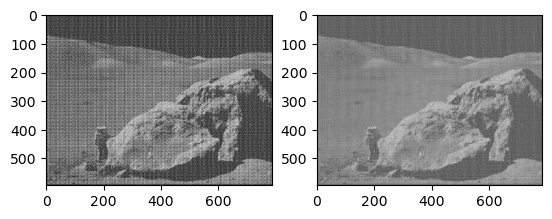

In [213]:
plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.subplot(122)
plt.imshow(img_idft, cmap='gray')
plt.show()